In [1]:
%load_ext autoreload
%autoreload 2

# Task 4.7 - Capacity Assessment

We estimate the probability that the daily cargo throughput exceeds the operational capacity of
650,000 tons/day, both today and over the next decade.

All simulations use the seasonal compound Poisson model: monthly arrival rates per vessel type, and a
lognormal cargo distribution per vessel type, all estimated with the method of moments.

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from toolkit import load_data, moments, fit_lognormal, fit_gamma, fit_normal, simDailyCPP, EmpiricalDist
np.random.seed(42)

In [ ]:
df = load_data()
d = df['Arrival_Date']

vessel_types = ["Container", "Tanker", "Bulk"]
month_lengths = [31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31]

days_per_month = d.dt.normalize().drop_duplicates().dt.month.value_counts().sort_index()
monthly_rates = (
    df.groupby(['Arrival_Month', 'Vessel_Type'], observed=True)
      .size()
      .unstack()
      .div(days_per_month, axis=0)
)[vessel_types]

moments_for_types = [moments(df[df['Vessel_Type'] == t]['Cargo_tons']) for t in vessel_types]
dists = tuple(fit_lognormal(mom) for mom in moments_for_types)

capacity = 650000

## Growth over the next decade

The dataset covers only three years and shows no trend between them, so the growth rate cannot be
estimated from the data. We therefore assume an annual growth of $g = 2\%$ in the amount of cargo,
which after $y$ years multiplies the expected throughput by $F_y = (1 + g)^y$. This growth can come
about in two ways, which we compare directly:

- **More arrivals:** more vessels arrive, each carrying the same amount of cargo as today. The arrival
  rate of vessel type $v$ in month $m$ becomes $\lambda_{v,m}(y) = F_y \, \lambda_{v,m}$.
- **Larger cargo:** the same number of vessels arrive, but each carries $F_y$ times as much cargo,
  $X_v(y) = F_y \, X_v$. For the lognormal distribution this only shifts $\mu_v$ by $\ln F_y$.

Both raise the expected throughput by the same factor $F_y$, but they affect its variance differently.
In the seasonal model from 4.4, $\text{Var}[S(t)] = \sum_v \Lambda_v(t) \, E[X_v^2]$: more arrivals
multiply $\Lambda_v(t)$, and with it the variance, by $F_y$, while larger cargo multiplies $E[X_v^2]$,
and with it the variance, by $F_y^2$. For every year $y$ we simulate the daily throughput under both
mechanisms and record how often it exceeds the capacity of 650,000 tons/day. Year $y = 0$ is the
current situation.

In [16]:
g = 0.02
years = range(0, 11)
nsim = 60

base_lambdas = [tuple(monthly_rates.loc[m, vessel_types]) for m in range(1, 13)]

rows = []
np.random.seed(42)
for y in years:
    F = (1 + g) ** y
    mechanisms = {
        'More arrivals': ([tuple(F * np.array(lam)) for lam in base_lambdas], dists),
        'Larger cargo': (base_lambdas, tuple(fit_lognormal((F * M1, F**2 * M2)) for M1, M2 in moments_for_types)),
    }
    for name, (grown_lambdas, grown_dists) in mechanisms.items():
        S = np.zeros((nsim, 365))
        for i in range(nsim):
            S[i] = simDailyCPP(grown_lambdas, grown_dists, month_lengths)[:, 7]

        rows.append({
            'Growth': name,
            'Year': y,
            'Factor': F,
            'Mean': np.mean(S),
            'Std': np.std(S, ddof=1),
            'P(S > 650k)': np.mean(S > capacity),
        })

growth_df = pd.DataFrame(rows)
growth_df['Days > 650k per year'] = growth_df['P(S > 650k)'] * 365
growth_df.round(4)

,Growth,Year,Factor,Mean,Std,P(S > 650k),Days > 650k per year
0,More arrivals,0,1.0000,393373.7516,127543.8840,0.0326,11.9167
1,Larger cargo,0,1.0000,394343.8359,127251.0680,0.0332,12.1167
2,More arrivals,1,1.0200,401419.2529,128806.7800,0.0382,13.9500
3,Larger cargo,1,1.0200,401844.4788,128249.3287,0.0370,13.5000
4,More arrivals,2,1.0404,409168.2233,129867.2477,0.0424,15.4667
5,Larger cargo,2,1.0404,408498.4512,131999.5668,0.0444,16.2167
6,More arrivals,3,1.0612,418781.7957,132396.5325,0.0511,18.6667
7,Larger cargo,3,1.0612,417953.3424,134800.2874,0.0535,19.5333
8,More arrivals,4,1.0824,426906.1781,132795.4401,0.0559,20.4167
9,Larger cargo,4,1.0824,426617.4001,136756.6026,0.0610,22.2500


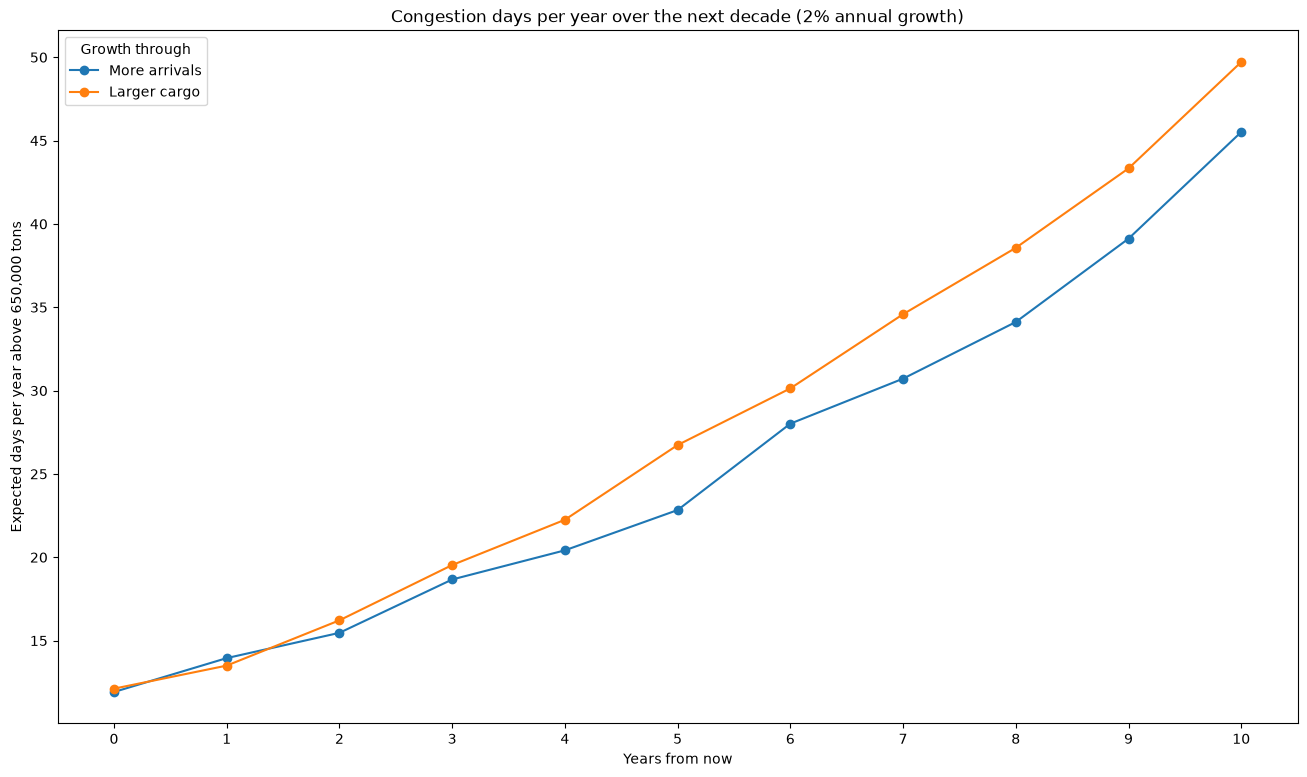

In [ ]:
fig, ax = plt.subplots(figsize = (16, 9))

for name in ['More arrivals', 'Larger cargo']:
    rows_g = growth_df[growth_df['Growth'] == name]
    ax.plot(rows_g['Year'], rows_g['Days > 650k per year'], marker='o', label=name)

ax.set_title("Congestion days per year over the next decade (2% annual growth)")
ax.set_xlabel("Years from now")
ax.set_ylabel("Expected days per year above 650,000 tons")
ax.set_xticks(list(years))
ax.legend(title="Growth through")

fig.savefig("figures/growth_scenarios.png", bbox_inches='tight', dpi=300)

In [20]:
decade_df = (
    growth_df[growth_df['Year'].isin([0, 10])]
      .set_index(['Year', 'Growth'])
      [['Factor', 'Mean', 'Std', 'P(S > 650k)', 'Days > 650k per year']]
)
decade_df.round(4)
decade_df.round(3).to_latex("tables/growth_scenarios.tex")

## Sensitivity to the cargo distribution

The results above use a lognormal distribution for the cargo of every vessel type. To see how much
they depend on this choice, we repeat the simulation of the current situation (the seasonal model,
year 0) with three other cargo distributions:

- **Normal for all types:** the normal distribution, which we rejected in 4.3, instead of the
  lognormal for every vessel type, also estimated with the method of moments. Since the normal
  distribution is symmetric and allows negative values, this shows how much the results change
  when the right tail of the cargo weights is modelled poorly.
- **Best fitting distributions:** the lognormal for Container and Tanker vessels, and the gamma
  distribution for Bulk vessels, which fitted Bulk best in 4.3. Both are estimated with the method of moments.
- **Empirical distributions:** no fitted distribution at all. The cargo of each vessel is resampled
  with replacement from the observed cargo weights of its type, so every observed weight is drawn with
  probability $1/n$. This is equivalent to sampling from the empirical CDF of the data.

The figure first compares the empirical CDF of each vessel type with the fitted lognormal and gamma CDFs.

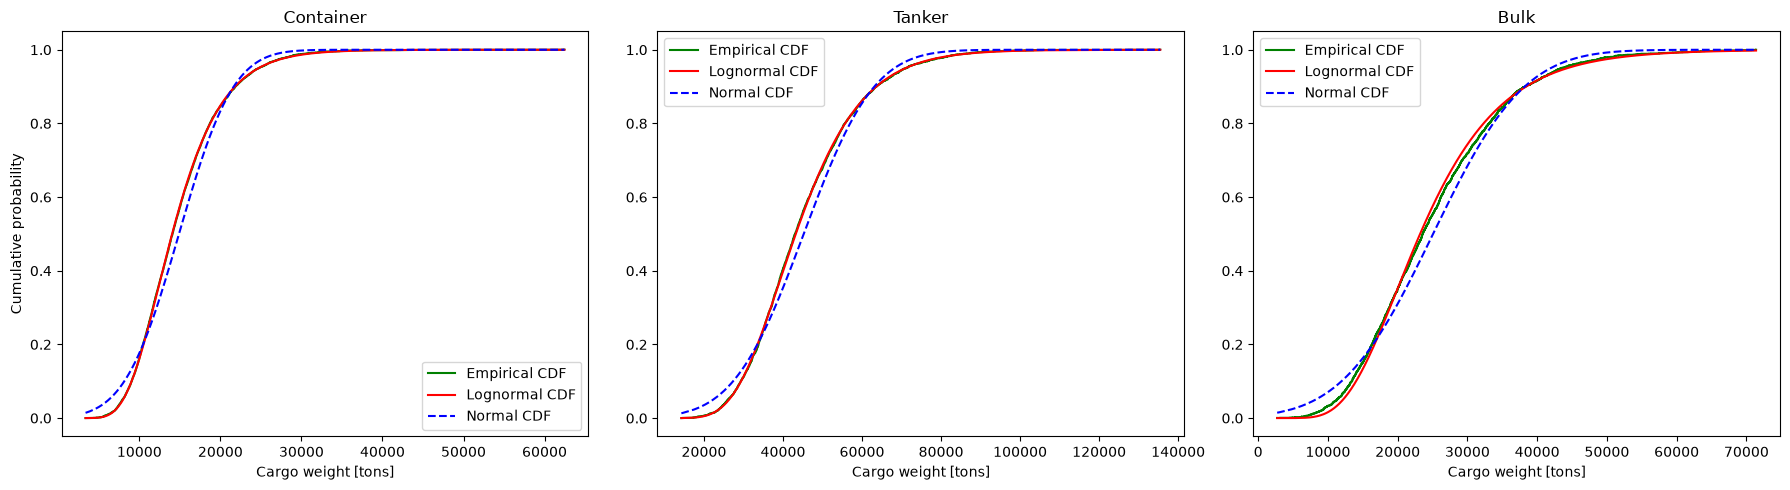

In [23]:
fig, ax = plt.subplots(figsize = (18, 5), ncols=3)

for i, (t, mom) in enumerate(zip(vessel_types, moments_for_types)):
    data = df[df['Vessel_Type'] == t]['Cargo_tons']
    ecdf = EmpiricalDist(data)

    ax[i].step(ecdf.ecdfx, ecdf.ecdfy, color='g', where='post', label='Empirical CDF')
    ax[i].plot(ecdf.ecdfx, fit_lognormal(mom).cdf(ecdf.ecdfx), color='r', label='Lognormal CDF')
    ax[i].plot(ecdf.ecdfx, fit_normal(mom).cdf(ecdf.ecdfx), color='b', linestyle='--', label='Normal CDF')
    ax[i].set_title(t)
    ax[i].set_xlabel("Cargo weight [tons]")
    ax[i].legend()

ax[0].set_ylabel("Cumulative probability")
plt.tight_layout()
fig.savefig("figures/cargo_cdfs.png", bbox_inches='tight', dpi=300)

In [22]:
seasonal_lambdas = [tuple(monthly_rates.loc[m, vessel_types]) for m in range(1, 13)]

cargo_models = {
    'Lognormal (model)': dists,
    'Normal (all types)': tuple(fit_normal(mom) for mom in moments_for_types),
    'Best fit (gamma for Bulk)': (dists[0], dists[1], fit_gamma(moments_for_types[2])),
    'Empirical': tuple(EmpiricalDist(df[df['Vessel_Type'] == t]['Cargo_tons']) for t in vessel_types),
}

nsim_sens = 1000
sens_rows = []
for name, cargo_dists in cargo_models.items():
    np.random.seed(42)   # same seed for every model, so the cell gives the same result however it is run
    S = np.zeros((nsim_sens, 365))
    for i in range(nsim_sens):
        S[i] = simDailyCPP(seasonal_lambdas, cargo_dists, month_lengths)[:, 7]

    sens_rows.append({
        'Cargo distribution': name,
        'Mean': np.mean(S),
        'Std': np.std(S, ddof=1),
        '95th quantile': np.quantile(S, 0.95),
        '99th quantile': np.quantile(S, 0.99),
        'P(S > 650k)': np.mean(S > capacity),
        'Days > 650k per year': np.mean(S > capacity) * 365,
    })

sensitivity_df = pd.DataFrame(sens_rows).set_index('Cargo distribution')
sensitivity_df.round(4)

,Mean,Std,95th quantile,99th quantile,P(S > 650k),Days > 650k per year
Cargo distribution,,,,,,
Lognormal (model),393952.3012,127010.6072,618308.7958,728889.8368,0.0324,11.841
Normal (all types),393957.5731,126998.2404,618084.3001,727902.8455,0.0323,11.777
Best fit (gamma for Bulk),393717.2672,126914.9735,617936.3547,727773.7663,0.0322,11.767
Empirical,393782.5044,127062.9904,618217.0500,728800.1500,0.0323,11.798


In [24]:
sensitivity_df.round(3).to_latex("tables/sensitivity_analysis.tex")

## Discussion

Will fill out all of these when I start writing the report tbh

### Probability of exceeding capacity


### Operational implications


### Sensitivity to assumptions


### Limitations


### Outlook for the next decade and recommended actions

